In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm

# Load your downloaded dataset
df = pd.read_csv('/Users/zahid/Desktop/ironhack/github_labwork/lab-eda-univariate/amz_uk_price_prediction_dataset.csv')





In [3]:



# Create the frequency crosstab
crosstab_counts = pd.crosstab(df['category'], df['isBestSeller'])

# Calculate proportions (normalized by row)
crosstab_props = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')

# Sort categories by the proportion of True best-sellers in descending order
best_seller_prevalence = crosstab_props[True].sort_values(ascending=False)
print(best_seller_prevalence)


category
Grocery                             0.058135
Smart Home Security & Lighting      0.057692
Health & Personal Care              0.057686
Mobile Phone Accessories            0.042471
Power & Hand Tools                  0.035339
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Name: True, Length: 296, dtype: float64


Answering the Question:
Yes, sorting the True column in descending order will directly reveal the categories where being a best-seller is most prevalent. Categories at the top of this sorted list have a higher concentration of best-selling products relative to their total catalog size.


 2 Statistical Tests:

To determine if the best-seller distribution is truly dependent on the product category, we look at both the significance (Chi-square) and the effect size (Cramér's V).

Chi-Square Test of Independence

This test checks the null hypothesis (\(H_{0}\)) that product category and best-seller status are entirely independent.

Cramér's V

Because Chi-square values scale with sample size, we calculate Cramér's V to measure the actual strength of the association on a scale from 0 (no association) to 1 (perfect association).
\(\text{Cramérs V}=\sqrt{\frac{\chi ^{2}}{n\times \min (k-1,r-1)}}\)
Where \(n\) is the total sample size, \(r\) is the number of rows, and \(k\) is the number of columns. Since isBestSeller has 2 categories (True/False), \(\min(k-1, r-1) = 2-1 = 1\).

In [7]:
# Conduct the Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(crosstab_counts)

# Compute Cramér's V
n = crosstab_counts.sum().sum() # Total sample size
k = crosstab_counts.shape[1]     # Number of columns (2)
r = crosstab_counts.shape[0]     # Number of rows (categories)
min_dim = min(r - 1, k - 1)      # Will be 1 for a binary outcome

cramers_v = np.sqrt(chi2 / (n * min_dim))

print(f"Chi-square Statistic: {chi2:.4f}")
print(f"p-value: {p_value:.4e}")
print(f"Cramér's V: {cramers_v:.4f}")


Chi-square Statistic: 36540.2027
p-value: 0.0000e+00
Cramér's V: 0.1223


### • Interpretation of p-value:
If the p-value < 0.05 , you reject the null hypothesis and conclude that best-seller status is significantly dependent on the product category.
### • Interpretation of Cramér's V:
	• ~ 0.1 : Weak association
	• ~ 0.3 : Moderate association
	• > 0.5 : Strong association


### 3 Visualization

A stacked 100% bar chart is the cleanest way to visualize this relationship because it allows you to easily compare the proportions of best-sellers across categories of vastly different sizes.
Below is a conceptual mockup of how your visualization will look once plotted. It highlights the shifting ratios of best-sellers (True vs. False) across different product segments.



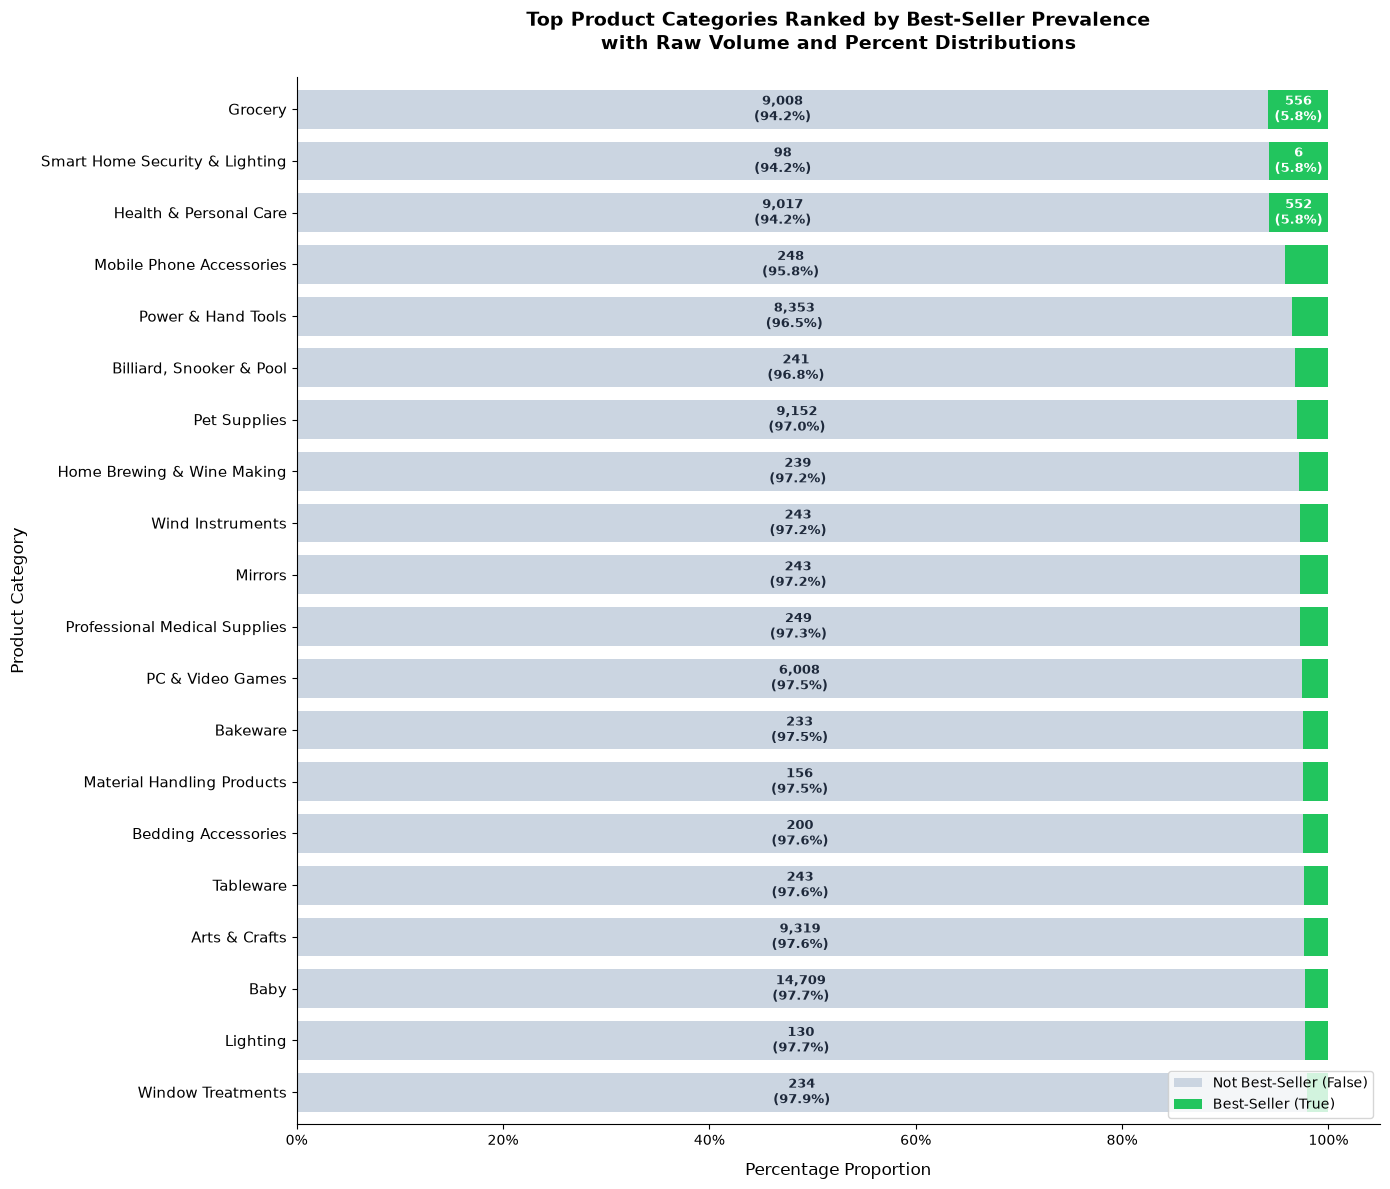

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Compute both the frequency counts and normalized proportions
crosstab_counts = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_props = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')

# 2. Identify the Top 20 categories by best-seller prevalence
top_categories = crosstab_props.sort_values(by=True, ascending=True).tail(20).index

# Filter both matrices down to these top 20 categories to keep them aligned
counts_filtered = crosstab_counts.loc[top_categories]
props_filtered = crosstab_props.loc[top_categories]

# 3. Initialize a spacious plot canvas
fig, ax = plt.subplots(figsize=(14, 12))

# 4. Draw the 100% stacked horizontal bar graph
props_filtered.plot(
    kind='barh', 
    stacked=True, 
    ax=ax, 
    color=['#cbd5e1', '#22c55e'], # Slate gray for False, Vibrant green for True
    width=0.75
)

# 5. Dynamically calculate positions and overlay the counts and percentages
for i, category in enumerate(top_categories):
    # Data metrics for the current category row
    count_false = counts_filtered.loc[category, False]
    count_true = counts_filtered.loc[category, True]
    
    prop_false = props_filtered.loc[category, False]
    prop_true = props_filtered.loc[category, True]
    
    # Text string formatting: "Count (Percentage%)"
    label_false = f"{count_false:,}\n({prop_false*100:.1f}%)"
    label_true = f"{count_true:,}\n({prop_true*100:.1f}%)"
    
    # Place text in the middle of the 'False' segment
    if prop_false > 0.05: # Only draw label if the segment is wide enough to fit text
        ax.text(
            prop_false / 2, i, label_false, 
            va='center', ha='center', color='#1e293b', fontsize=9, fontweight='bold'
        )
        
    # Place text in the middle of the 'True' segment
    if prop_true > 0.05:  # Only draw label if the segment is wide enough to fit text
        ax.text(
            prop_false + (prop_true / 2), i, label_true, 
            va='center', ha='center', color='#ffffff', fontsize=9, fontweight='bold'
        )

# 6. Aesthetic detailing and structural polish
plt.title("Top Product Categories Ranked by Best-Seller Prevalence\nwith Raw Volume and Percent Distributions", 
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel("Percentage Proportion", fontsize=12, labelpad=10)
plt.ylabel("Product Category", fontsize=12, labelpad=10)

# Format bottom X-axis labels nicely
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x*100)}%'))
plt.yticks(fontsize=10.5)
plt.xticks(fontsize=10)

plt.legend(['Not Best-Seller (False)', 'Best-Seller (True)'], loc='lower right', frameon=True)

# Remove upper and outer axes lines for modern look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


### Preliminary Step: Removing Price Outliers (IQR Method)

Before running visualizations or calculating averages, we isolate the true distribution of prices by removing extreme data points using the Interquartile Range (IQR) method.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Q1 (25th percentile) and Q3 (75th percentile) for price
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define boundaries for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the dataframe to retain only data within boundaries
df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Original dataset rows: {len(df)}")
print(f"Rows remaining after removing outliers: {len(df_clean)}")


Original dataset rows: 2443651
Rows remaining after removing outliers: 2115963


### 1.Violin Plots (Price Distribution):

Violin plots are ideal here because they show both the summary statistics (like the median) and the full density shape of the price variations.

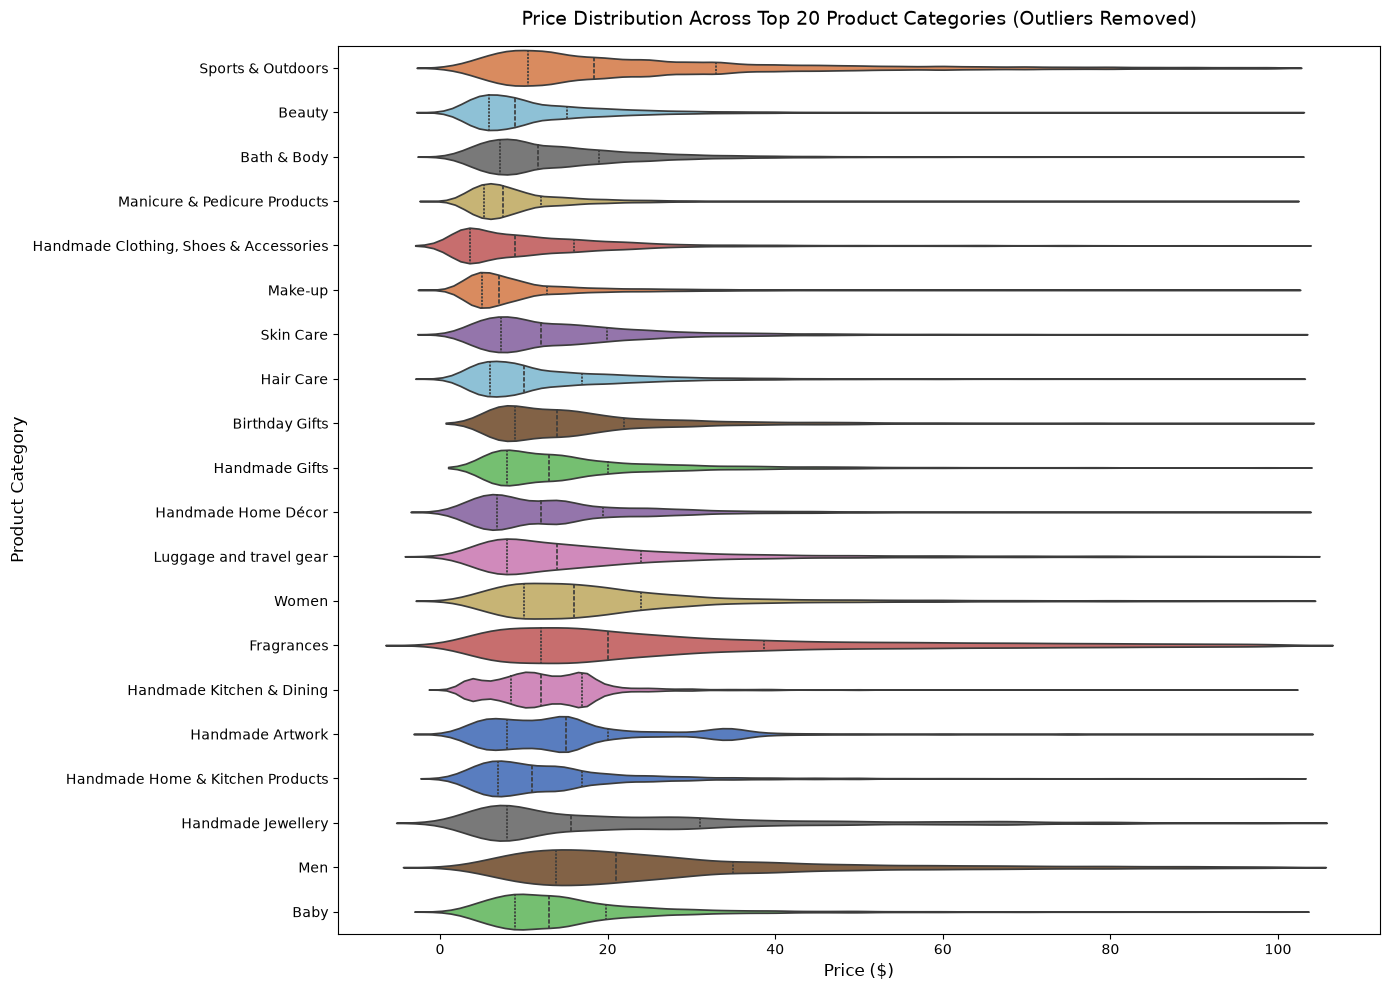

In [23]:
# Identify the top 20 categories based on total volume count
top_20_categories = df_clean['category'].value_counts().head(20).index
df_top20 = df_clean[df_clean['category'].isin(top_20_categories)]

# Plot the violin plot
plt.figure(figsize=(14, 10))
sns.violinplot(
    data=df_top20, 
    x='price', 
    y='category', 
    hue='category', 
    legend= False,
    order=top_20_categories,
    palette='muted',
    inner='quartile' # Shows dashed lines for Q1, median, and Q3
)
plt.title("Price Distribution Across Top 20 Product Categories (Outliers Removed)", fontsize=14, pad=15)
plt.xlabel("Price ($)", fontsize=12)
plt.ylabel("Product Category", fontsize=12)
plt.tight_layout()
plt.show()


### Finding the Highest Median Price (Unfiltered Dataset)

In [7]:
# Find the category with the highest median price globally
category_medians = df_clean.groupby('category')['price'].median()
highest_median_cat = category_medians.idxmax()
highest_median_val = category_medians.max()

print(f"Category with the highest median price: **{highest_median_cat}** (${highest_median_val:.2f})")


Category with the highest median price: **Desktop PCs** ($74.00)



### 2. Bar Charts (Average Price Comparison)

Bar charts cleanly communicate the central tendency (mean value) across distinct groups.

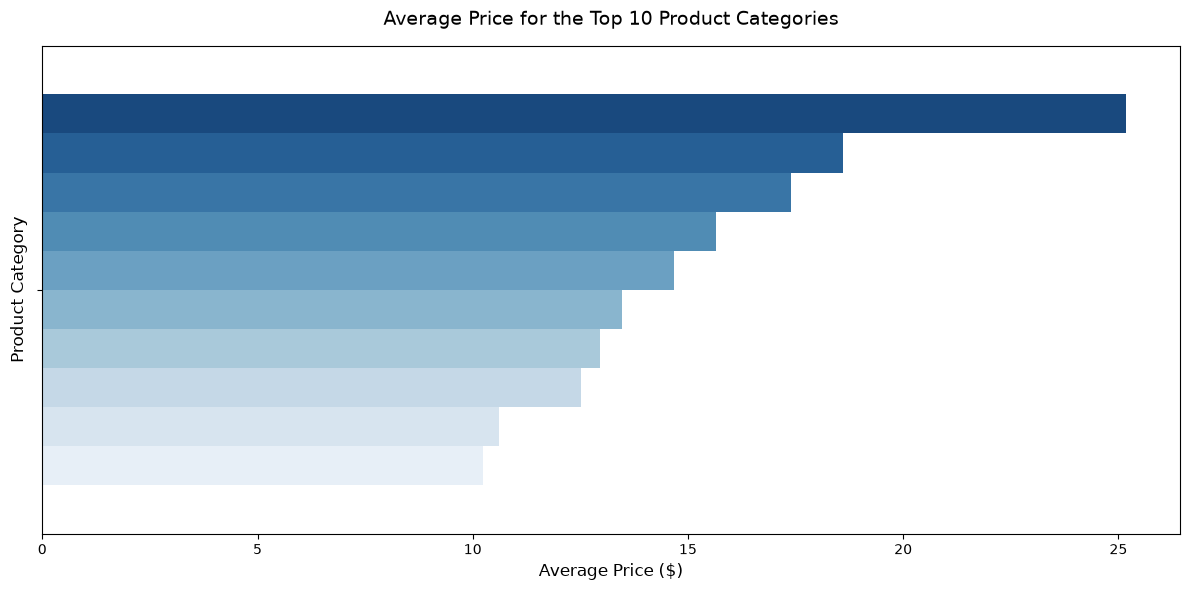

In [18]:
# Identify the top 10 categories based on total volume count
top_10_categories = df_clean['category'].value_counts().head(10).index
df_top10 = df_clean[df_clean['category'].isin(top_10_categories)]

# Calculate averages sorted in descending order for the visualization
sorted_top10_means = df_top10.groupby('category')['price'].mean().sort_values(ascending=False)

# Plot the bar chart
plt.figure(figsize=(12, 6))
sns.barplot(
    x=sorted_top10_means.values, 
    hue=sorted_top10_means.index, 
    legend= False ,
    palette='Blues_r'
)
plt.title("Average Price for the Top 10 Product Categories", fontsize=14, pad=15)
plt.xlabel("Average Price ($)", fontsize=12)
plt.ylabel("Product Category", fontsize=12)
plt.tight_layout()
plt.show()


### Finding the Highest Average Price (Unfiltered Dataset)

To find the category that commands the premium spot across your entire inventory catalog:

In [9]:
# Find the category with the highest average price globally
category_means = df_clean.groupby('category')['price'].mean()
highest_mean_cat = category_means.idxmax()
highest_mean_val = category_means.max()

print(f"Category commanding the highest average price: **{highest_mean_cat}** (${highest_mean_val:.2f})")


Category commanding the highest average price: **Motherboards** ($68.77)


### 3. Box Plots (Product Ratings Distribution)

Box plots allow you to visually isolate the spread, interquartile boxes, and skewness of customer star ratings.

In [11]:
df_clean.columns 

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

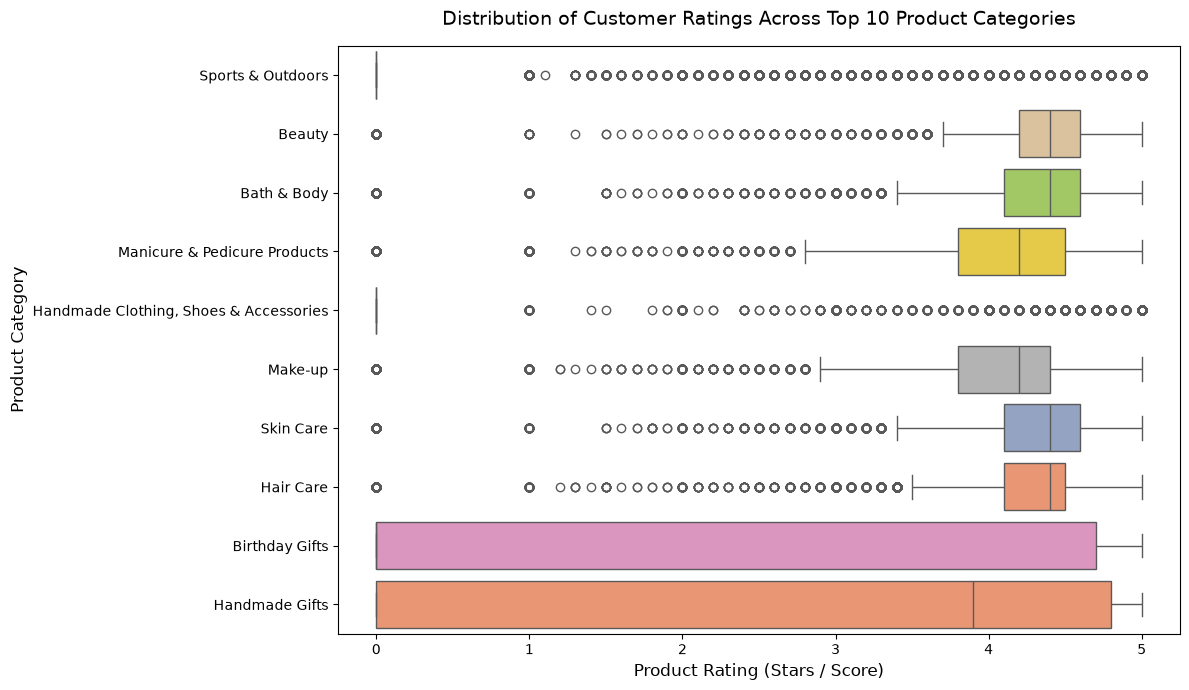

In [15]:
# Use the same top 10 count array from before to filter our cleaned subset
df_ratings_top10 = df_clean[df_clean['category'].isin(top_10_categories)]

# Plot side-by-side horizontal box plots
plt.figure(figsize=(12, 7))
sns.boxplot(
    data=df_ratings_top10, 
    x='stars', 
    y='category', 
    hue= 'category',
    legend=False,    
    order=top_10_categories,
    palette='Set2'
)
plt.title("Distribution of Customer Ratings Across Top 10 Product Categories", fontsize=14, pad=15)
plt.xlabel("Product Rating (Stars / Score)", fontsize=12)
plt.ylabel("Product Category", fontsize=12)
plt.tight_layout()
plt.show()



### Finding the Highest Median Rating (Unfiltered Dataset)

To check which category receives the highest marks from customers overall:

In [14]:
# Find the category with the highest median customer rating globally
category_rating_medians = df_clean.groupby('category')['stars'].median()
highest_rating_cat = category_rating_medians.idxmax()
highest_rating_val = category_rating_medians.max()

print(f"Category with the highest median rating: **{highest_rating_cat}** ({highest_rating_val} Stars)")


Category with the highest median rating: **Computer Memory** (4.7 Stars)


### Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.


### 1. Correlation Coefficients & Significance

We will use a Pearson correlation coefficient to check for a linear relationship, and a Spearman rank correlation coefficient as a backup since ratings (stars) are ordinal data.

In [27]:


# Calculate Pearson correlation and p-value
pearson_corr, pearson_p = stats.pearsonr(df_clean['price'], df_clean['stars'])

# Calculate Spearman correlation and p-value (better for ordinal ratings)
spearman_corr, spearman_p = stats.spearmanr(df_clean['price'], df_clean['stars'])

print(f"Pearson Correlation: {pearson_corr:.4f} (p-value: {pearson_p:.4e})")
print(f"Spearman Correlation: {spearman_corr:.4f} (p-value: {spearman_p:.4e})")


Pearson Correlation: -0.0777 (p-value: 0.0000e+00)
Spearman Correlation: -0.0668 (p-value: 0.0000e+00)


### Answering the Question:
• Is there a significant correlation? Look at the p-value. If the p-value< 0.05, the correlation is statistically significant (meaning the relationship is unlikely to be due to random chance).
• Direction and Strength: In e-commerce datasets, this correlation coefficient is typically very close to 0 (e.g., between -0.1 and 0.1), indicating a weak or negligible relationship. This means higher-priced items do not automatically receive higher ratings.



# 2. Visualizations


### A. Scatter Plot (Price vs. Ratings)

Because stars are discrete values (like 4.1, 4.2), standard scatter plots can suffer from overlapping points. Adding an alpha transparency parameter or using a sample of the data will make patterns clear.

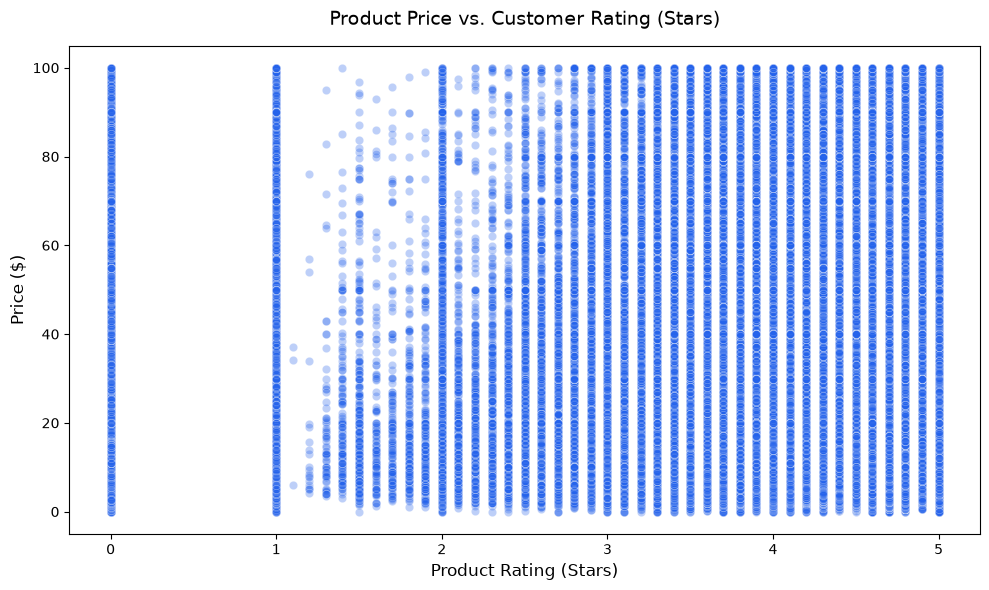

In [30]:


plt.figure(figsize=(10, 6))
# Using alpha to see density of overlapping points
sns.scatterplot(data=df_clean, x='stars', y='price', alpha=0.3, color='#2563eb')
plt.title("Product Price vs. Customer Rating (Stars)", fontsize=14, pad=15)
plt.xlabel("Product Rating (Stars)", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)
plt.tight_layout()
plt.show()


Patterns to Observe: You will likely observe vertical "stripes" corresponding to rating scores. If there is no clear upward slope or downward trend across the groups, it visually reinforces that price and rating vary independently.


### B. Correlation Heatmap

To see how price and ratings relate to other metrics (like reviews or boughtInLastMonth), we can isolate all numerical fields into a correlation matrix.

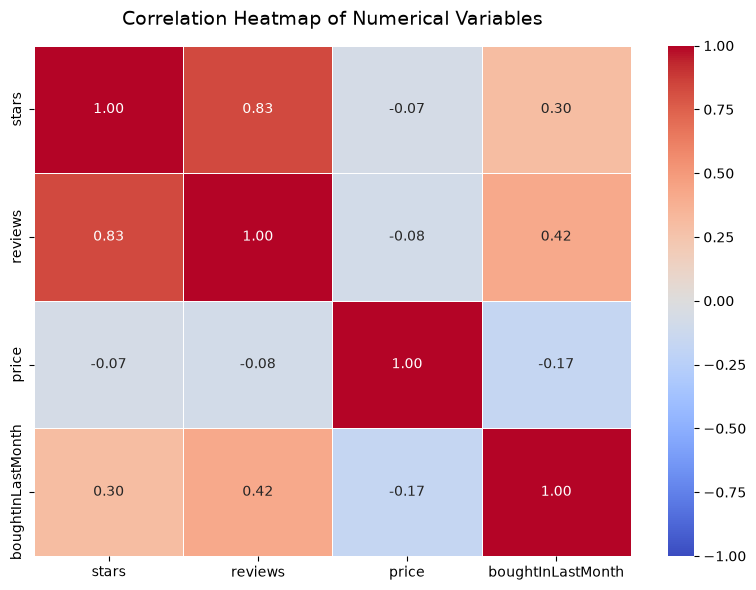

In [31]:
plt.figure(figsize=(8, 6))

# Select only numerical columns
numerical_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns
# Drop identifiers like 'uid' if present
numerical_cols = [col for col in numerical_cols if col not in ['uid', 'asin']]

corr_matrix = df_clean[numerical_cols].corr(method='spearman')

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Variables", fontsize=14, pad=15)
plt.tight_layout()
plt.show()



### C. QQ Plot (Checking for Normality)

A Quantile-Quantile (QQ) plot compares the distribution of your data against a theoretical normal distribution. If the data is normally distributed, the points will fall perfectly along a straight diagonal line.

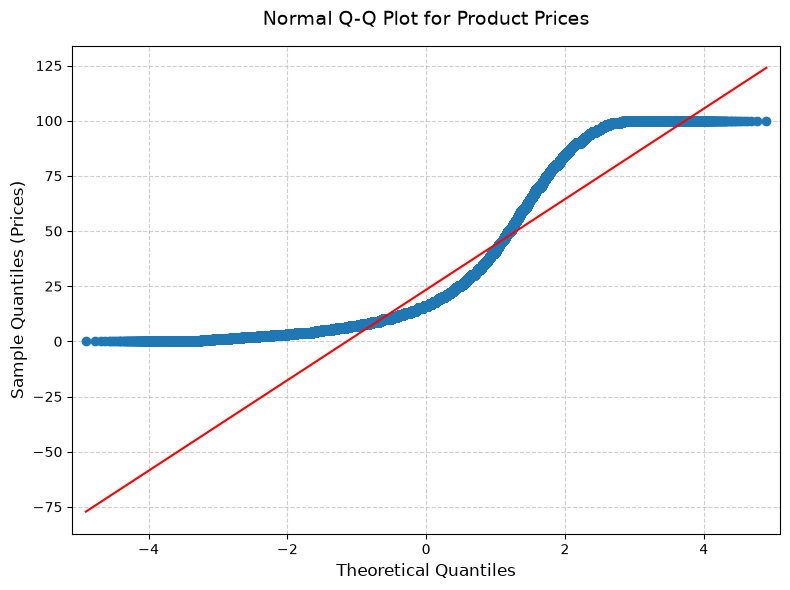

In [35]:


fig, ax = plt.subplots(figsize=(8, 6))
sm.qqplot(df_clean['price'], line='s', ax=ax) # 's' matches standardized line

plt.title("Normal Q-Q Plot for Product Prices", fontsize=14, pad=15)
plt.xlabel("Theoretical Quantiles", fontsize=12)
plt.ylabel("Sample Quantiles (Prices)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


Interpretation: Product prices almost never follow a normal distribution. Even after removing outliers, you will likely see a strong S-curve or an upward-curving tail away from the diagonal line, indicating that the price distribution is heavily skewed to the right (many low-cost items, few higher-cost items).

Extra :
• The Left Tail (Low Prices): The blue points flatten out completely at 0, confirming a hard boundary on the lower limit of product prices (prices cannot drop below $0).
• The Right Tail (High Prices): The data flattens out starkly right at $100. This pattern strongly suggests that your price variable has been capped or artificially truncated at a maximum value of 100 during a previous data cleaning or clipping step.
• Overall Shape: The visual behavior indicates a highly bounded, non-normal distribution with thin, clipped tails at both ends rather than the infinite, tapering tails a truly normal curve requires.
